# Baseline Atlas-DeePC

**Restored historical benchmark: Clarabel, $\lambda_g=0.05$, one rollout worker.**
The saved 1,000-seed run reports **33.60 ms median**, **36.39 ms mean**, and
**78.56 ms P99** total online computation per step. These are historical measurements,
not a guarantee of fresh runtime. The original charts, plots, and videos are retained.

This version uses 48 physical charts, rank-60 uncentered linear-subspace bases,
iterative terminal-reference augmentation with N=10, and graph waypoints. Every
action comes from DeePC, without contextual rescue or fitted dynamics.

This notebook reads the frozen `linear_iterative_n10_v1` results with an explicit
regularization setting. Simulation and media regeneration are disabled to protect
the historical benchmark. The newer OSQP notebook is preserved in
`archive/notebooks/baseline_osqp_before_clarabel_restore_20260915.ipynb`.

A no-graph-waypoints comparison using the same Clarabel and lambda_g=0.05 settings is available in Section 4.4.


In [1]:
import json
import os
import sys
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "baseline_atlas_deepc.py").is_file())
assert (ROOT / "src/baseline_atlas_deepc.py").exists(), "Open from the project root"
sys.path.insert(0, str(ROOT / "src"))
import baseline_atlas_deepc as baseline
import routed_deepc_experiment as experiment

DATA_PATH, ATLAS_PATH = baseline.DATA_PATH, baseline.ATLAS_PATH
SAVED_BASELINE_VERSION = "linear_iterative_n10_v1"
RESULT_ROOT = ROOT / "experiments/routed_deepc_iid/baseline_linear_iterative_n10_v1"
RESULT_ROOT.mkdir(parents=True, exist_ok=True)
EVALUATION_SEEDS = list(range(211, 1211))  # Python stop is exclusive; change this range.
assert EVALUATION_SEEDS and len(EVALUATION_SEEDS) == len(set(EVALUATION_SEEDS))
from baseline_notebook_media import ALL_SEEDS
DIAGNOSTIC_SEEDS = list(ALL_SEEDS)
RUN_EVALUATION = False
RUN_DIAGNOSTICS = False
OVERWRITE = False
EVAL_DIR = RESULT_ROOT / "evaluation_1000"
DIAGNOSTIC_DIR = RESULT_ROOT / "diagnostics"
from dataclasses import replace
config = replace(baseline.default_config(), lam_g=0.05)
SOLVER = "CLARABEL"
H = np.load(DATA_PATH, mmap_mode="r")
atlas = experiment.load_atlas(ATLAS_PATH)
if RUN_DIAGNOSTICS:
    raise RuntimeError("Historical saved-result notebook: simulation reruns are disabled to protect the archived benchmark.")
if RUN_EVALUATION:
    from baseline_1000_benchmark import run_panel as run_timed_baseline
    raise RuntimeError("Historical saved-result notebook: use a separate fresh benchmark for new timings.")
print("Baseline version:", SAVED_BASELINE_VERSION)
print("Full evaluation requested:", len(EVALUATION_SEEDS), "seeds; enabled:", RUN_EVALUATION)


Baseline version: linear_iterative_n10_v1
Full evaluation requested: 1000 seeds; enabled: False


## 1. Local linear-subspace DeePC

For each chart, collect its complete offline columns $X_k$ and compute the rank-60
left SVD basis **without subtracting a mean**: $X_k=U_k\Sigma_k V_k^\top$.
The cached matrix fed to DeePC is $B_k=U_k(:,1:60)$, with zero affine offset:

$$\begin{bmatrix}u_{\mathrm{ini}}\\u\\y_{\mathrm{ini}}+\sigma\\y\end{bmatrix}=B_k g.$$

The matrix includes all $U_p,U_f,Y_p,Y_f$ rows. The empirical coefficient bounds
and regularization use the same rules as before, evaluated in the new coordinates.
There is no centering or sum-to-one constraint. Only the current chart's basis is used.

### Iterative terminal-reference augmentation
1. Once the target is known, find the 10 eligible offline configurations with nearest
   fingertip positions. The original 6 cm source-episode-target separation rule remains.
2. At every time step, locate the current physical chart and choose the candidate chart
   with smallest directed route cost from that current chart. Within a chart, keep the
   nearest fingertip candidate; ties use the offline index.
3. Construct the full terminal reference from that candidate's posture, zero velocity,
   and the requested fingertip target. Reconstruct the route using cached shortest paths.
4. Track the next chart's medoid until the fingertip comes within 7 cm; then permanently
   use the terminal-reference mode. **Candidate selection continues after this switch**, so
   the terminal posture is allowed to change online. No new goal-freezing rule is added.

The top-10 target-neighborhood search occurs once per rollout. Online reselection compares
only the candidate charts, not all Hankel columns. The graph supplies references, never actions.


In [2]:
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=1):
    controller = baseline.BaselineAtlasDeePC(H, atlas, config)
chart0_matrix, chart0_columns = controller.matrix_cache[(0,)]
assert len(controller.matrix_cache) == 48
assert all(not np.any(matrix["offset"]) for matrix, _ in controller.matrix_cache.values())
assert all(matrix["basis"].shape[1] == 60 for matrix, _ in controller.matrix_cache.values())
display(pd.Series({
    "charts": config.clusters, "chart geometry": "uncentered linear subspace",
    "SVD rank": config.svd_rank, "candidate count": baseline.CANDIDATE_COUNT,
    "terminal selection": "minimum route cost, recomputed every step",
    "chart 0 matrix": str(chart0_matrix["basis"].shape),
    "chart 0 support columns": len(chart0_columns),
    "DeePC matrix": "current chart only", "contextual rescue": False,
}))


charts                                                            48
chart geometry                            uncentered linear subspace
SVD rank                                                          60
candidate count                                                   10
terminal selection         minimum route cost, recomputed every step
chart 0 matrix                                             (144, 60)
chart 0 support columns                                          607
DeePC matrix                                      current chart only
contextual rescue                                              False
dtype: object

## 2. Inspecting the constructed physical-configuration atlas

A chart is defined by K-means on the latest periodic joint configuration

$$
\phi(y_t)=[\cos q_1,\cos q_2,\sin q_1,\sin q_2,\cos(q_1+q_2),\sin(q_1+q_2)].
$$

Inputs, velocities, fingertip coordinates, and the preceding output are not used to assign charts. Each panel below overlays 32 randomly sampled chart members in a shallow color and draws the chart medoid boldly. This is the updated 48-chart version of the configuration-cloud plot.


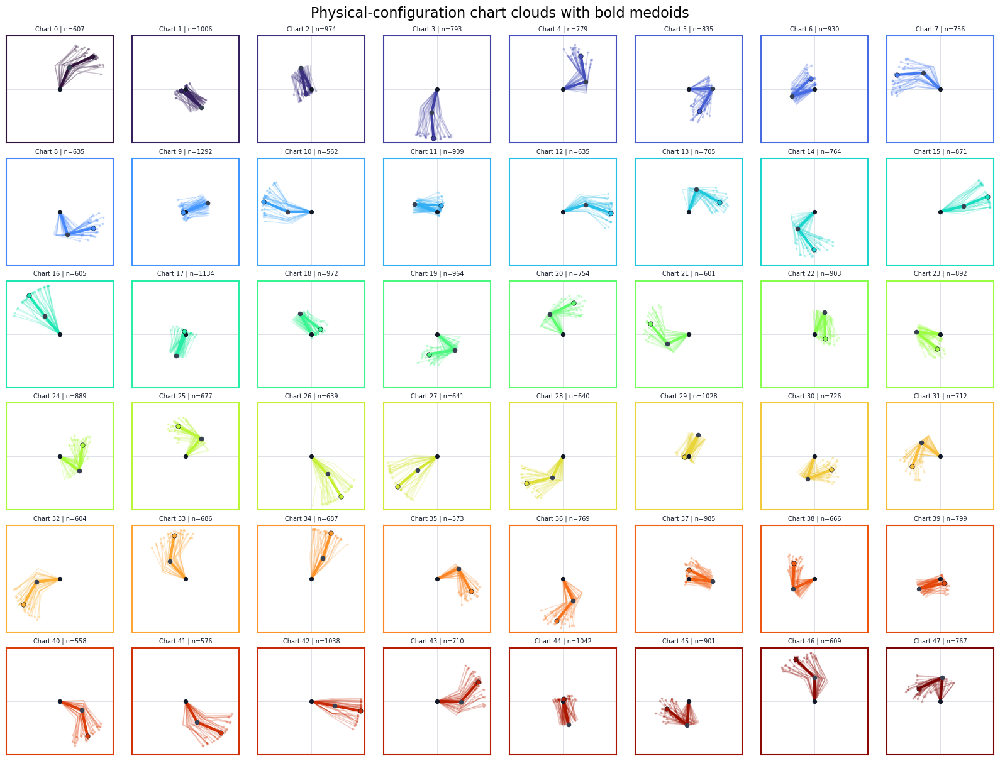

Medoid forward-kinematics consistency: max 0.505 mm
Chart occupancy: min 558, median 760, max 1292 windows


In [3]:
from matplotlib.collections import LineCollection

chart_sizes = np.bincount(atlas["labels"].astype(int), minlength=config.clusters)
medoid_states = np.asarray(atlas["medoid_states"], dtype=float)
chart_colors = plt.cm.turbo(np.linspace(0.0, 1.0, config.clusters))
chart_output_states = H[experiment.pipe.M * experiment.pipe.L:].reshape(
    experiment.pipe.L, experiment.pipe.P, H.shape[1]
)[experiment.pipe.T_INI - 1].T
cloud_members_per_chart = 32
cloud_rng = np.random.default_rng(17)

# Reacher-v5's output geometry is approximately 0.10 m to the elbow and
# 0.11 m from the elbow to the reported fingertip site.
link_1, link_2 = 0.10, 0.11
elbows = link_1 * np.column_stack([medoid_states[:, 0], medoid_states[:, 2]])
fk_fingertips = elbows + link_2 * np.column_stack([medoid_states[:, 8], medoid_states[:, 9]])
stored_fingertips = medoid_states[:, 6:8]
fk_error = np.linalg.norm(fk_fingertips - stored_fingertips, axis=1)

fig, axes = plt.subplots(6, 8, figsize=(16, 12), constrained_layout=True)
for chart_id, ax in enumerate(axes.flat):
    elbow = elbows[chart_id]
    fingertip = stored_fingertips[chart_id]
    color = chart_colors[chart_id]
    member_indices = np.flatnonzero(atlas["labels"] == chart_id)
    sampled_indices = cloud_rng.choice(
        member_indices, size=min(cloud_members_per_chart, member_indices.size), replace=False
    )
    cloud_states = chart_output_states[sampled_indices]
    cloud_elbows = link_1 * np.column_stack([cloud_states[:, 0], cloud_states[:, 2]])
    cloud_fingertips = cloud_states[:, 6:8]
    cloud_segments = np.stack([
        np.zeros_like(cloud_elbows), cloud_elbows, cloud_fingertips
    ], axis=1)
    ax.add_collection(LineCollection(
        cloud_segments, colors=[color], linewidths=1.05, alpha=0.24, zorder=1
    ))
    ax.scatter(cloud_fingertips[:, 0], cloud_fingertips[:, 1], s=7,
               color=color, alpha=0.32, linewidth=0, zorder=1)
    ax.plot([0, elbow[0], fingertip[0]], [0, elbow[1], fingertip[1]],
            color=color, linewidth=3.0, solid_capstyle="round", zorder=3)
    ax.scatter([0], [0], s=18, color="#111827", zorder=3)
    ax.scatter([elbow[0]], [elbow[1]], s=20, color="#374151", zorder=3)
    ax.scatter([fingertip[0]], [fingertip[1]], s=28, color=color,
               edgecolor="#111827", linewidth=0.5, zorder=4)
    ax.axhline(0, color="#d1d5db", linewidth=0.5, zorder=0)
    ax.axvline(0, color="#d1d5db", linewidth=0.5, zorder=0)
    ax.set_xlim(-0.225, 0.225)
    ax.set_ylim(-0.225, 0.225)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"Chart {chart_id} | n={chart_sizes[chart_id]}", fontsize=7, color="#111827")
    for spine in ax.spines.values():
        spine.set_color(color)
        spine.set_linewidth(1.5)
fig.suptitle("Physical-configuration chart clouds with bold medoids", fontsize=16)
medoid_plot_path = RESULT_ROOT / "physical48_chart_configuration_clouds.png"
fig.savefig(medoid_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Medoid forward-kinematics consistency: max {1000 * fk_error.max():.3f} mm")
print(f"Chart occupancy: min {chart_sizes.min()}, median {np.median(chart_sizes):.0f}, max {chart_sizes.max()} windows")


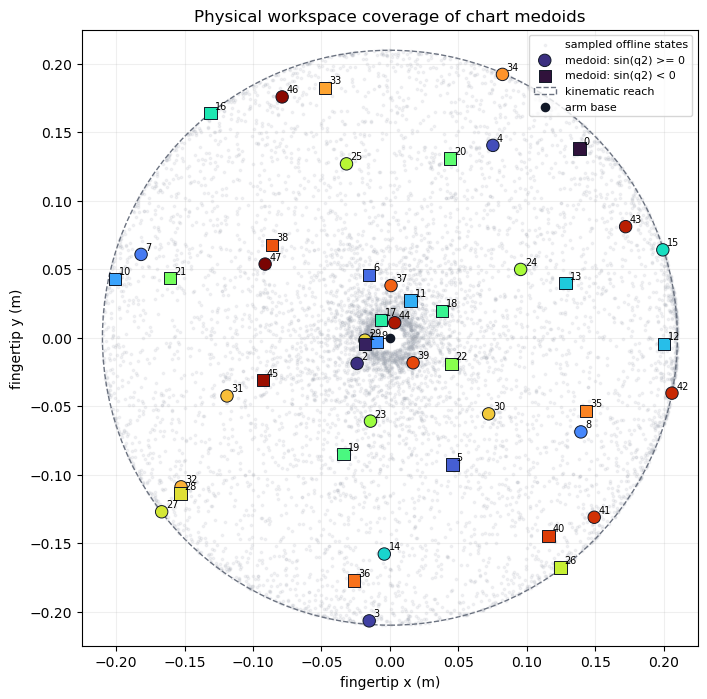

In [4]:
Y_windows = H[experiment.pipe.M * experiment.pipe.L:].reshape(
    experiment.pipe.L, experiment.pipe.P, H.shape[1]
)
offline_fingertips = Y_windows[experiment.pipe.T_INI - 1, 6:8].T
workspace_sample = np.linspace(0, offline_fingertips.shape[0] - 1, 8000, dtype=int)
elbow_up = medoid_states[:, 3] >= 0.0  # sign of sin(q2)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(offline_fingertips[workspace_sample, 0], offline_fingertips[workspace_sample, 1],
           s=3, color="#9ca3af", alpha=0.12, label="sampled offline states")
for mask, marker, label in [(elbow_up, "o", "medoid: sin(q2) >= 0"),
                            (~elbow_up, "s", "medoid: sin(q2) < 0")]:
    ax.scatter(stored_fingertips[mask, 0], stored_fingertips[mask, 1],
               c=chart_colors[mask], marker=marker, s=80, edgecolor="#111827",
               linewidth=0.7, label=label, zorder=3)
for chart_id, (x, y) in enumerate(stored_fingertips):
    ax.annotate(str(chart_id), (x, y), xytext=(3, 3), textcoords="offset points", fontsize=7)
ax.add_patch(plt.Circle((0, 0), link_1 + link_2, fill=False, linestyle="--",
                        color="#6b7280", linewidth=1, label="kinematic reach"))
ax.scatter([0], [0], color="#111827", s=35, label="arm base", zorder=4)
ax.set_aspect("equal")
ax.set_xlim(-0.225, 0.225)
ax.set_ylim(-0.225, 0.225)
ax.set_xlabel("fingertip x (m)")
ax.set_ylabel("fingertip y (m)")
ax.set_title("Physical workspace coverage of chart medoids")
ax.grid(alpha=0.2)
ax.legend(loc="upper right", fontsize=8)
workspace_plot_path = RESULT_ROOT / "atlas_workspace_coverage.png"
fig.savefig(workspace_plot_path, dpi=160, bbox_inches="tight")
plt.show()

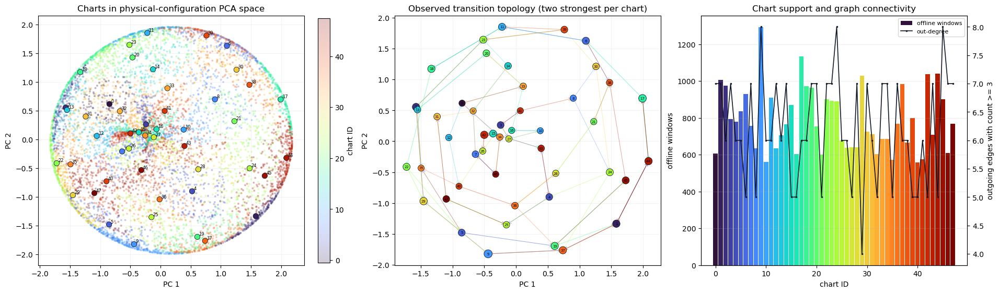

Active clustering coordinates: 6
PCA variance captured: 38.1%
Directed routing edges retained by the controller: 298
Outgoing-degree range: 4 to 8


In [5]:
from sklearn.decomposition import PCA

clustering_features, _, _ = experiment.behavioral_features(
    H,
    config.clustering_input_weight,
    config.clustering_feature_mode,
    config.clustering_configuration_weight,
    config.clustering_velocity_weight,
    config.clustering_fingertip_weight,
)
active_feature_mask = clustering_features.std(axis=0) > 1e-10
gate_features = clustering_features[:, active_feature_mask]
gate_centers = atlas["centers"][:, active_feature_mask]
pca = PCA(n_components=2)
gate_pca = pca.fit_transform(gate_features)
center_pca = pca.transform(gate_centers)
history_sample = np.linspace(0, gate_pca.shape[0] - 1, 8000, dtype=int)
transition_counts = np.asarray(atlas["transition_counts"], dtype=int)
edge_mask = transition_counts >= config.edge_count_threshold
np.fill_diagonal(edge_mask, False)
out_degree = edge_mask.sum(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), constrained_layout=True)
scatter = axes[0].scatter(gate_pca[history_sample, 0], gate_pca[history_sample, 1],
                          c=atlas["labels"][history_sample], cmap="turbo",
                          vmin=-0.5, vmax=config.clusters - 0.5, s=4, alpha=0.22)
axes[0].scatter(center_pca[:, 0], center_pca[:, 1], c=chart_colors, s=55,
                edgecolor="#111827", linewidth=0.6)
for chart_id, (x, y) in enumerate(center_pca):
    axes[0].annotate(str(chart_id), (x, y), xytext=(2, 2),
                     textcoords="offset points", fontsize=6)
axes[0].set_title("Charts in physical-configuration PCA space")
axes[0].set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")
axes[0].grid(alpha=0.15)
fig.colorbar(scatter, ax=axes[0], label="chart ID", fraction=0.046)

# Show the two strongest observed outgoing transitions per chart. The router
# itself retains every edge meeting the count threshold.
for source in range(config.clusters):
    destinations = np.flatnonzero(edge_mask[source])
    if destinations.size:
        strongest = destinations[np.argsort(transition_counts[source, destinations])[-2:]]
        for destination in strongest:
            strength = transition_counts[source, destination]
            axes[1].annotate("", xy=center_pca[destination], xytext=center_pca[source],
                             arrowprops=dict(arrowstyle="->", color=chart_colors[source],
                                             alpha=min(0.75, 0.18 + strength / 250),
                                             linewidth=0.7))
node_sizes = 35 + 90 * chart_sizes / chart_sizes.max()
axes[1].scatter(center_pca[:, 0], center_pca[:, 1], c=chart_colors, s=node_sizes,
                edgecolor="#111827", linewidth=0.6, zorder=3)
for chart_id, (x, y) in enumerate(center_pca):
    axes[1].annotate(str(chart_id), (x, y), ha="center", va="center", fontsize=5, zorder=4)
axes[1].set_title("Observed transition topology (two strongest per chart)")
axes[1].set_xlabel("PC 1")
axes[1].set_ylabel("PC 2")
axes[1].grid(alpha=0.15)

chart_ids = np.arange(config.clusters)
axes[2].bar(chart_ids, chart_sizes, color=chart_colors, width=0.9, label="offline windows")
axes[2].set_xlabel("chart ID")
axes[2].set_ylabel("offline windows")
axes[2].set_title("Chart support and graph connectivity")
axes[2].grid(axis="y", alpha=0.2)
degree_axis = axes[2].twinx()
degree_axis.plot(chart_ids, out_degree, color="#111827", linewidth=1.2,
                 marker=".", markersize=3, label="out-degree")
degree_axis.set_ylabel("outgoing edges with count >= 3")
lines_1, labels_1 = axes[2].get_legend_handles_labels()
lines_2, labels_2 = degree_axis.get_legend_handles_labels()
axes[2].legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right", fontsize=8)

topology_plot_path = RESULT_ROOT / "physical48_atlas_topology.png"
fig.savefig(topology_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print("Active clustering coordinates:", gate_features.shape[1])
print("PCA variance captured:", f"{100 * pca.explained_variance_ratio_.sum():.1f}%")
print("Directed routing edges retained by the controller:", int(edge_mask.sum()))
print("Outgoing-degree range:", int(out_degree.min()), "to", int(out_degree.max()))


### How to read these views

- The shallow arm clouds show posture variation inside each chart, while the bold arm is the medoid. Because assignment uses the current periodic joint configuration, each chart is now directly interpretable as a compact physical-posture neighborhood.
- The workspace plot checks physical coverage and reveals both elbow branches. A medoid is not a target and does not imply that its source trajectory was successful.
- The PCA view is only a two-dimensional projection of the six active configuration coordinates. Overlap in this view does not mean the original chart assignments overlap.
- Node size and support bars show how many complete input-output Hankel columns back each chart. The topology panel draws only two strong outgoing edges per node; online routing uses every observed directed edge with count at least three.


## 3. Current-version result and fairness audit

Only `linear_iterative_n10_v1` rollouts are accepted here. If the requested evaluation
panel has not been run, the notebook shows the explicitly labeled diagnostic set.
Neither old fixed-reference results nor the affine iterative experiment are loaded.


In [6]:
evaluation_runs = []
evaluation_path = EVAL_DIR / "summary.json"
if evaluation_path.exists():
    payload = json.loads(evaluation_path.read_text())
    assert payload["method"] == SAVED_BASELINE_VERSION
    by_seed = {int(r["seed"]): r for r in payload["results"]}
    evaluation_runs = [by_seed[s] for s in EVALUATION_SEEDS if s in by_seed]
missing_seeds = sorted(set(EVALUATION_SEEDS) - {r["seed"] for r in evaluation_runs})
if missing_seeds:
    print(f"Requested evaluation is incomplete: {len(missing_seeds)} missing seeds. No full-panel success estimate is reported.")
    result_summary = json.loads((DIAGNOSTIC_DIR / "summary.json").read_text())
    panel_name = "Diagnostic validation only (not a success-rate benchmark)"
    runs = result_summary["results"]
else:
    result_summary = payload
    panel_name = "Requested baseline evaluation"
    runs = evaluation_runs
assert result_summary["method"] == SAVED_BASELINE_VERSION
from dataclasses import asdict
assert result_summary["signature"]["config"] == {k: v for k, v in asdict(config).items() if k != "seed"}
assert all(r["baseline_version"] == SAVED_BASELINE_VERSION and r["matrix_geometry"] == "linear" and r["candidate_count"] == 10 for r in runs)
assert all(r["dynamic_terminal_reference"] for r in runs)
audit = result_summary["fairness_audit"]
assert audit["offline_stabilized_episode_count"] == 0
assert all(r["minimum_selected_goal_source_separation"] >= config.goal_source_target_min_distance for r in runs)
assert all(not r["fitted_dynamics_model"] and not r["feedback_fallback"] for r in runs)
display(pd.Series({
    "displayed panel": panel_name,
    "offline seed range": str(audit["data_seed_range"]),
    "stabilized offline episodes": audit["offline_stabilized_episode_count"],
    "minimum source-target separation (m)": min(r["minimum_selected_goal_source_separation"] for r in runs),
    "per-step full-library retrieval": "none",
    "one-time target-conditioned state search": "top 10 eligible configurations",
}))


displayed panel                              Requested baseline evaluation
offline seed range                                            [2026, 2225]
stabilized offline episodes                                              0
minimum source-target separation (m)                              0.060162
per-step full-library retrieval                                       none
one-time target-conditioned state search    top 10 eligible configurations
dtype: object

## 4. Baseline results and timing

Strict success requires mean error below 1 cm and maximum error below 2 cm over both
the final-30 and final-100 windows. The initial diagnostic panel is intentionally small
and includes previously investigated cases; it cannot establish a general success rate.
Timings wrap the complete online controller call; QP time includes problem construction
and solution. One-time goal-neighborhood setup is separate.


Requested baseline evaluation


,seed,strict success,final-30 (mm),final-100 (mm),minimum (mm),goal sample changes,online median (ms),QP median (ms),goal selection median (ms),one-time goal setup (ms),unsolved steps
0,211,True,1.364,1.364,1.364,0,33.578,33.444,0.016,5.355,0
1,212,True,2.045,2.045,1.419,0,34.375,34.252,0.016,4.934,0
2,213,True,3.010,3.010,1.882,0,33.944,33.804,0.017,4.679,0
3,214,True,0.686,0.686,0.207,0,33.826,33.706,0.014,7.539,0
4,215,True,1.128,1.128,1.128,0,35.648,35.427,0.015,5.719,0
5,216,True,0.242,0.242,0.074,0,34.877,34.729,0.014,5.620,0
6,217,True,3.335,3.335,0.241,0,35.907,35.704,0.015,4.869,0
7,218,True,3.628,3.628,3.628,0,37.617,37.358,0.015,7.192,0
8,219,True,1.494,1.494,1.494,0,44.238,44.014,0.015,5.120,0
9,220,True,1.546,1.546,1.546,0,40.866,40.712,0.015,7.609,0


Strict success: 928/1000


,seed,failure type,minimum (mm),final-30 (mm),final-100 (mm)
21,232,Failed strict test; 1 cm <= minimum error <2 cm,13.480972,13.480972,13.480972
34,245,Failed strict test; minimum error <1 cm,5.959589,15.016033,15.016033
36,247,Failed strict test; 1 cm <= minimum error <2 cm,13.374597,13.374597,13.374597
41,252,Failed strict test; minimum error >=2 cm,33.625068,45.254214,45.254214
77,288,Failed strict test; 1 cm <= minimum error <2 cm,13.428387,13.428387,13.428387
...,...,...,...,...,...
925,1136,Failed strict test; 1 cm <= minimum error <2 cm,12.713162,12.713162,12.713162
929,1140,Failed strict test; 1 cm <= minimum error <2 cm,16.062141,16.062141,16.062141
948,1159,Failed strict test; minimum error >=2 cm,26.329158,30.641541,30.641541
968,1179,Failed strict test; 1 cm <= minimum error <2 cm,14.011664,14.011664,14.011664


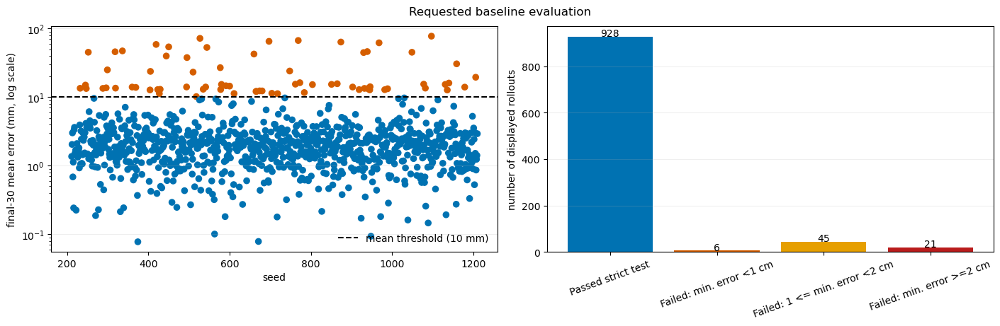

In [7]:
results = pd.DataFrame([{
    "seed": r["seed"], "strict success": bool(r["success_30"] and r["success_100"]),
    "final-30 (mm)": 1000*r["mean_last_30"], "final-100 (mm)": 1000*r["mean_last_100"],
    "minimum (mm)": 1000*r["minimum"],
    "goal sample changes": r["goal_sample_switches"],
    "online median (ms)": r["median_control_compute_time_ms"],
    "QP median (ms)": r["median_solve_time_ms"],
    "goal selection median (ms)": r["median_goal_selection_time_ms"],
    "one-time goal setup (ms)": r["goal_setup_time_ms"],
    "unsolved steps": r["unsolved_steps"],
} for r in runs])
print(panel_name)
display(HTML("<details><summary>Show per-seed results</summary>"
             + results.style.format({c: "{:.3f}" for c in results if "(mm)" in c or "(ms)" in c}).to_html()
             + "</details>"))
if not missing_seeds:
    print(f"Strict success: {results['strict success'].sum()}/{len(results)}")
failures = results.loc[~results["strict success"]].copy()
failures["failure type"] = np.select(
    [failures["minimum (mm)"] < 10, failures["minimum (mm)"] < 20],
    ["Failed strict test; minimum error <1 cm", "Failed strict test; 1 cm <= minimum error <2 cm"],
    default="Failed strict test; minimum error >=2 cm")
display(failures[["seed", "failure type", "minimum (mm)", "final-30 (mm)", "final-100 (mm)"]])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
axes[0].scatter(results["seed"], results["final-30 (mm)"], s=35,
                c=np.where(results["strict success"], "#0072B2", "#D55E00"))
axes[0].axhline(10, color="black", linestyle="--", label="mean threshold (10 mm)")
axes[0].set(xlabel="seed", ylabel="final-30 mean error (mm, log scale)", yscale="log")
axes[0].legend(frameon=False)
failure_counts = pd.Series({
    "Passed strict test": int(results["strict success"].sum()),
    "Failed: min. error <1 cm": int((failures["minimum (mm)"] < 10).sum()),
    "Failed: 1 <= min. error <2 cm": int(((failures["minimum (mm)"] >= 10) & (failures["minimum (mm)"] < 20)).sum()),
    "Failed: min. error >=2 cm": int((failures["minimum (mm)"] >= 20).sum()),
})
axes[1].bar(failure_counts.index, failure_counts.values, color=["#0072B2", "#D55E00", "#E69F00", "#b91c1c"])
axes[1].set_ylabel("number of displayed rollouts")
axes[1].tick_params(axis="x", rotation=20)
for i, value in enumerate(failure_counts):
    axes[1].text(i, value + 0.1, str(value), ha="center")
for ax in axes:
    ax.grid(alpha=0.2, axis="y")
fig.suptitle(panel_name)
fig.savefig(RESULT_ROOT / "current_baseline_results.png", dpi=160)
plt.show()


### 4.1. 1,000-seed success-rate test

This test uses seeds **211--1210** for the current **linear-subspace + iterative-N=10**
baseline. Both final-30 and final-100 windows must have mean fingertip error below
1 cm and maximum error below 2 cm. The success count and rate are reported only
when all 1,000 distinct seeds are available.

This section reads the completed historical 1,000-seed panel. New simulations are disabled in this restored view.

These seeds have been inspected in earlier ablations, so this is not a pristine
held-out test. The reported rate describes these 1,000 trials with the frozen
offline dataset.


baseline                                                 linear_iterative_n10_v1
seed range                                                             211--1210
requested trials                                                            1000
completed trials in summary                                                 1000
missing trials                                                                 0
result source                  /Users/kumiko/Projects/atlas_deepc_reacher/exp...
dtype: object

,trials,successes,failures,strict success rate
0,1000,928,72,92.8%


Failed seeds: [232, 245, 247, 252, 288, 296, 299, 318, 319, 336, 360, 369, 404, 405, 419, 423, 427, 429, 444, 450, 494, 495, 510, 518, 527, 535, 541, 544, 577, 578, 580, 591, 600, 611, 660, 665, 666, 674, 680, 697, 704, 718, 748, 762, 769, 773, 784, 804, 851, 865, 874, 903, 919, 930, 932, 939, 940, 945, 946, 968, 982, 989, 1049, 1078, 1082, 1097, 1131, 1136, 1140, 1159, 1179, 1206]


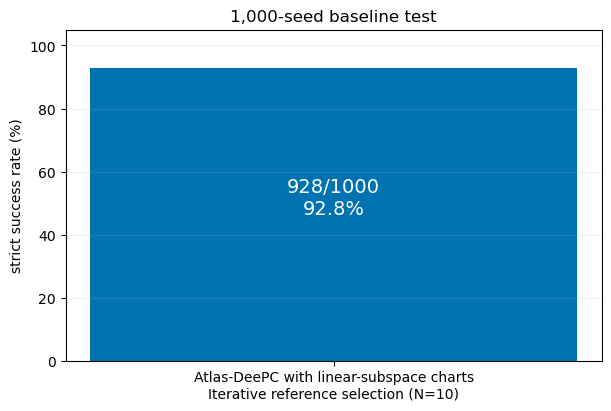

In [8]:
from baseline_success_rate import validate_panel as current_validate_panel, success_statistics
from types import FunctionType, SimpleNamespace
# Keep the existing provenance checks, scoped to this historical version only.
validate_panel = FunctionType(
    current_validate_panel.__code__,
    {**current_validate_panel.__globals__,
     "baseline": SimpleNamespace(BASELINE_VERSION=SAVED_BASELINE_VERSION)},
)

TEST_SEEDS = list(range(211, 1211))
assert len(TEST_SEEDS) == 1000 and len(set(TEST_SEEDS)) == 1000
RUN_1000_SEED_TEST = False
TEST_RESULT_DIR = RESULT_ROOT / "evaluation_1000"
TEST_SUMMARY_PATH = TEST_RESULT_DIR / "summary.json"

if RUN_1000_SEED_TEST:
    from baseline_1000_benchmark import run_panel as run_timed_baseline
    raise RuntimeError("Historical saved-result notebook: use a separate fresh benchmark for new timings.")

test_rows, test_missing = [], TEST_SEEDS.copy()
if TEST_SUMMARY_PATH.exists():
    test_payload = json.loads(TEST_SUMMARY_PATH.read_text())
    test_rows, test_missing = validate_panel(test_payload, TEST_SEEDS, config)
    from candidate_goal_routing_experiment import file_digest
    assert test_payload["signature"]["data_sha256"] == file_digest(DATA_PATH)
    assert test_payload["signature"]["atlas_sha256"] == file_digest(ATLAS_PATH)

display(pd.Series({
    "baseline": SAVED_BASELINE_VERSION,
    "seed range": f"{TEST_SEEDS[0]}--{TEST_SEEDS[-1]}",
    "requested trials": len(TEST_SEEDS),
    "completed trials in summary": len(test_rows),
    "missing trials": len(test_missing),
    "result source": str(TEST_SUMMARY_PATH),
}))
if test_missing:
    print("1,000-seed success rate: not available yet.")
    print("Set RUN_1000_SEED_TEST=True to run/resume the baseline panel, or point TEST_RESULT_DIR to completed current-baseline results.")
else:
    test_stats = success_statistics(test_rows)
    test_table = pd.DataFrame([{
        "trials": test_stats["trials"],
        "successes": test_stats["successes"],
        "failures": test_stats["failures"],
        "strict success rate": f"{test_stats['success_rate']:.1%}",
    }])
    display(test_table)
    print("Failed seeds:", [r["seed"] for r in test_rows if not (r["success_30"] and r["success_100"])])
    fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
    rate = 100 * test_stats["success_rate"]
    ax.bar([0], [rate], color="#0072B2", width=0.5)
    ax.set(ylim=(0, 105), ylabel="strict success rate (%)",
           xticks=[0], xticklabels=["Atlas-DeePC with linear-subspace charts\nIterative reference selection (N=10)"],
           title="1,000-seed baseline test")
    ax.text(0, max(3, rate/2), f"{test_stats['successes']}/1000\n{rate:.1f}%",
            ha="center", color="white", fontsize=14)
    ax.grid(axis="y", alpha=0.2)
    fig.savefig(TEST_RESULT_DIR / "success_rate_1000.png", dpi=160)
    plt.show()


### 4.2. Computation time by module

This benchmark runs one baseline rollout at a time with one numerical thread.
All 320 steps count toward success; timing statistics exclude a 10-step warm-up
on seed 210 and the first five steps of each evaluated rollout. The raw trace files
retain **every step's timers**, including those excluded from the timing aggregate.

The table reports pooled **mean, median, p95, and p99 milliseconds per step**.
The stacked plot uses means, so the module contributions add to the mean total.
Separate median and p99 plots use unstacked bars: module percentiles do not add
to the total percentile. Total latency percentiles are computed directly from
the measured total time at each step. P99 is the 99th percentile of timed steps.
The QP timer includes constructing the optimization problem, canonicalization,
and solution, not just the solver's internal iterations. Simulator stepping,
file saving, and video rendering are excluded from online computation.

One-time target-neighborhood construction and offline cache preparation are shown
separately. Wall-clock timings were taken on this shared computer and may be affected
by other running jobs; they are not an isolated cross-algorithm speed comparison.


,mean_ms,median_ms,p95_ms,p99_ms,share_of_mean_total
module,,,,,
Chart localization,0.0731,0.0659,0.1059,0.2054,0.20%
Terminal-reference selection,0.0159,0.0140,0.0198,0.0506,0.04%
Graph routing,0.0071,0.0060,0.0089,0.0241,0.02%
Linear subspace retrieval,0.0008,0.0008,0.0010,0.0013,0.00%
QP construction and solve,36.2584,33.4693,55.4513,78.3162,99.63%
Other control-loop work,0.0375,0.0325,0.0573,0.1175,0.10%
Total online control,36.3928,33.5974,55.6078,78.5593,100.00%


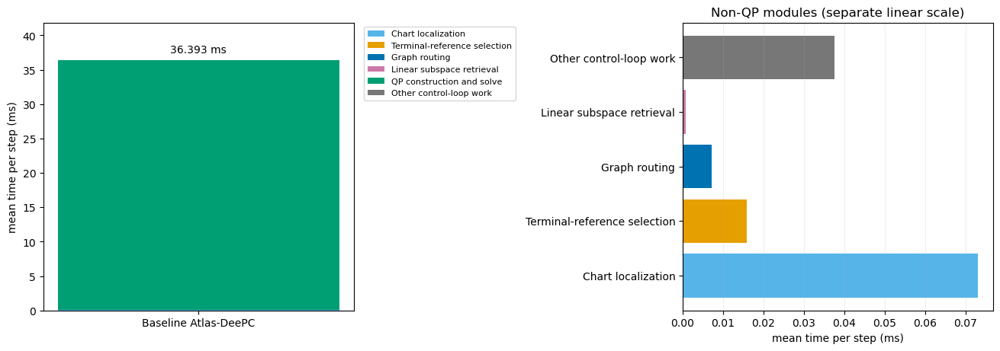

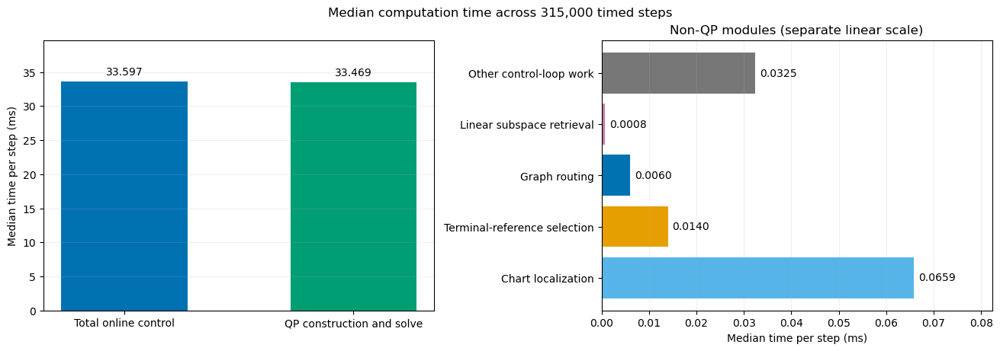

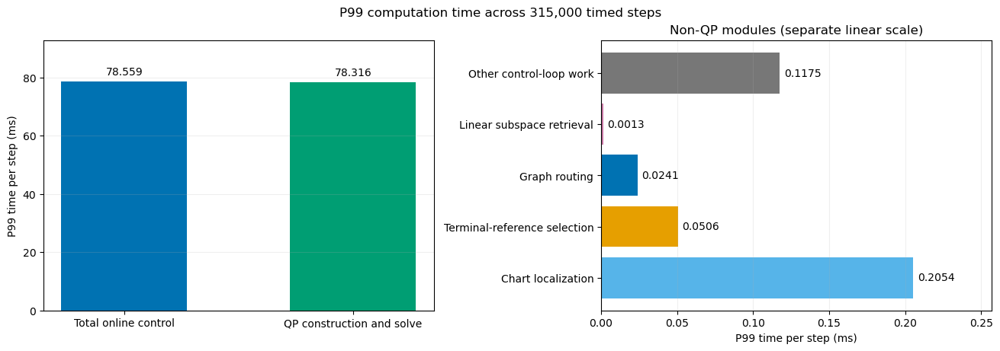

mean      6.191683
median    5.158875
p95       9.179906
Name: One-time goal-neighborhood setup per rollout (ms), dtype: float64

,session start UTC,data loading (s),atlas loading (s),source metadata (s),chart SVD + graph cache (s)
0,2026-09-08T16:52:38.177814+00:00,0.008616,0.002207,0.979833,0.145823


Timed control steps: 315000
Median across rollout-level medians (ms): 33.2022


In [9]:
TIMING_SUMMARY_PATH = TEST_RESULT_DIR / "timing_summary.json"
if test_missing or not TIMING_SUMMARY_PATH.exists():
    print("Complete 1,000-seed module timings are not available yet.")
else:
    test_timing = json.loads(TIMING_SUMMARY_PATH.read_text())
    if any("p99_ms" not in row for row in test_timing["modules"]):
        from baseline_1000_benchmark import summarize_timing
        refreshed = summarize_timing([TEST_RESULT_DIR / f"seed{s}_control_results.npz" for s in TEST_SEEDS])
        test_timing.update(refreshed)
        TIMING_SUMMARY_PATH.write_text(json.dumps(test_timing, indent=2))
    assert {int(r["seed"]) for r in test_timing["per_seed"]} == set(TEST_SEEDS)
    assert test_timing["timed_steps"] == len(TEST_SEEDS) * (config.steps - 5)
    module_table = pd.DataFrame(test_timing["modules"]).set_index("module")
    display(module_table.style.format({"mean_ms": "{:.4f}", "median_ms": "{:.4f}",
                                      "p95_ms": "{:.4f}", "p99_ms": "{:.4f}",
                                      "share_of_mean_total": "{:.2%}"}))
    modules = module_table.drop(index="Total online control")
    np.testing.assert_allclose(modules["mean_ms"].sum(), module_table.loc["Total online control", "mean_ms"], atol=1e-6)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
    palette = ["#56B4E9", "#E69F00", "#0072B2", "#CC79A7", "#009E73", "#777777"]
    bottom = 0.0
    for (name, row), color in zip(modules.iterrows(), palette):
        axes[0].bar([0], [row["mean_ms"]], bottom=bottom, color=color, label=name)
        bottom += row["mean_ms"]
    axes[0].set(xticks=[0], xticklabels=["Baseline Atlas-DeePC"], ylabel="mean time per step (ms)", ylim=(0, bottom*1.15))
    axes[0].text(0, bottom*1.03, f"{bottom:.3f} ms", ha="center")
    axes[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
    overhead = modules.drop(index="QP construction and solve")
    axes[1].barh(overhead.index, overhead["mean_ms"], color=[palette[i] for i in [0,1,2,3,5]])
    axes[1].set(xlabel="mean time per step (ms)", title="Non-QP modules (separate linear scale)")
    axes[1].grid(axis="x", alpha=0.2)
    fig.savefig(TEST_RESULT_DIR / "module_computation_time.png", dpi=160, bbox_inches="tight")
    plt.show()
    for statistic, label in [("median_ms", "Median"), ("p99_ms", "P99")]:
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
        main = module_table.loc[["Total online control", "QP construction and solve"], statistic]
        bars = axes[0].bar(["Total online control", "QP construction and solve"], main,
                           color=["#0072B2", "#009E73"], width=0.55)
        axes[0].bar_label(bars, fmt="%.3f", padding=4)
        axes[0].set(ylabel=f"{label} time per step (ms)", ylim=(0, main.max()*1.18))
        bars = axes[1].barh(overhead.index, overhead[statistic],
                            color=[palette[i] for i in [0, 1, 2, 3, 5]])
        axes[1].bar_label(bars, fmt="%.4f", padding=4)
        axes[1].set(xlabel=f"{label} time per step (ms)",
                    xlim=(0, overhead[statistic].max()*1.25),
                    title="Non-QP modules (separate linear scale)")
        axes[0].grid(axis="y", alpha=0.2)
        axes[1].grid(axis="x", alpha=0.2)
        fig.suptitle(f"{label} computation time across {test_timing['timed_steps']:,} timed steps")
        fig.savefig(TEST_RESULT_DIR / f"module_computation_time_{statistic}.png", dpi=160, bbox_inches="tight")
        plt.show()
    display(pd.Series(test_timing["one_time_goal_setup_ms"], name="One-time goal-neighborhood setup per rollout (ms)"))
    display(pd.DataFrame([{
        "session start UTC": s["started_utc"], **s["offline_setup_seconds"],
    } for s in test_timing["sessions"]]).rename(columns={
        "data_loading": "data loading (s)", "atlas_loading": "atlas loading (s)",
        "source_episode_metadata": "source metadata (s)",
        "linear_chart_cache_and_all_pairs_routes": "chart SVD + graph cache (s)",
    }))
    print("Timed control steps:", test_timing["timed_steps"])
    print("Median across rollout-level medians (ms):", round(test_timing["median_of_rollout_medians_ms"], 4))


### 4.3. Small ablation: nearest-fingertip terminal reference

**Question:** Does graph-route-cost selection of the terminal configuration help
compared with simply choosing the configuration whose fingertip is closest to the target?

**Paired setup:** 100 seeds, **211--310**, with 320 control steps per seed. The current
baseline's matching saved rollouts are reused; only the nearest-reference variant
was newly simulated. This is a subset of the 1,000-seed panel, not a new held-out test.

| Component | Current baseline | Nearest-fingertip ablation |
|---|---|---|
| Candidate search at initialization | 10 closest eligible configurations; deduplicate by chart | Single closest eligible configuration |
| Terminal configuration selection | Minimum route cost from the current chart; repeated each step | Nearest fingertip in Euclidean distance; fixed throughout rollout |
| Graph-based waypoint routing | Updated each step | Updated each step, unchanged |

**Everything else is held fixed:** the same offline data, 48 physical-configuration
charts, rank-60 linear-subspace bases, initial conditions and targets, output channels,
DeePC objective and constraints, and 7 cm terminal-mode latch. In both methods,
candidate eligibility requires the source episode's original target to be at least
6 cm from the online target. The selected reference uses the sampled joint posture,
zero joint velocities, and exact online target fingertip coordinates.

**Strict success:** both final-30 and final-100 windows must have mean fingertip
error below 1 cm and maximum error below 2 cm. No early termination is used.


,Terminal-reference policy,Successes / trials,Strict success rate
0,"N=10, minimum route cost (current baseline)",93/100,93.0%
1,Single nearest eligible fingertip (fixed),90/100,90.0%


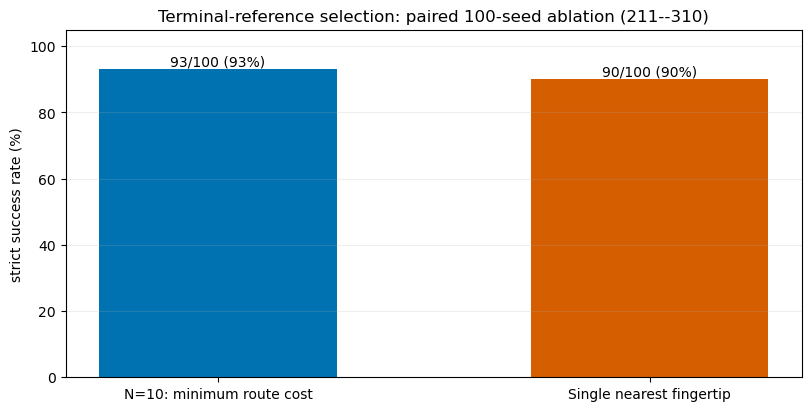

seed,Outcome with nearest reference,baseline final-100 (mm),nearest final-100 (mm)
231,Lost baseline success,3.933,49.918
236,Lost baseline success,1.084,70.505
290,Lost baseline success,0.444,11.510
298,Lost baseline success,2.908,62.084
299,Repaired baseline failure,25.009,3.423


Unsolved QP steps (nearest-reference variant): 0


In [10]:
ABLATION_DIR = ROOT / "experiments/routed_deepc_iid/ablation_nearest_terminal_linear_v1"
ABLATION_BASELINE_DIR = RESULT_ROOT / "evaluation_1000"
ABLATION_SEEDS = list(range(211, 311))
ablation_payload = json.loads((ABLATION_DIR / "summary.json").read_text())
ablation_baseline_payload = json.loads((ABLATION_BASELINE_DIR / "summary.json").read_text())
assert ablation_payload["method"] == "linear_fixed_nearest_eligible_terminal_v1"
for key in ("config", "data_sha256", "atlas_sha256", "source_sha256"):
    assert ablation_payload["signature"][key] == ablation_baseline_payload["signature"][key]
ablation_baseline_rows, missing_ablation = validate_panel(ablation_baseline_payload, ABLATION_SEEDS, config)
assert not missing_ablation
ablation_nearest_rows = ablation_payload["results"]
assert len(ablation_nearest_rows) == 100
assert {r["seed"] for r in ablation_nearest_rows} == set(ABLATION_SEEDS)
assert all(r["candidate_count"] == 1 and r["matrix_geometry"] == "linear"
           and r["steps"] == config.steps and not r["dynamic_terminal_reference"]
           and r["minimum_selected_goal_source_separation"] >= config.goal_source_target_min_distance
           for r in ablation_nearest_rows)
ablation_old = {r["seed"]: r for r in ablation_baseline_rows}
paired_records = []
for r in ablation_nearest_rows:
    old = ablation_old[r["seed"]]
    with np.load(ABLATION_BASELINE_DIR / f"seed{r['seed']}_control_results.npz", allow_pickle=True) as old_trace:
        with np.load(ABLATION_DIR / f"seed{r['seed']}_control_results.npz", allow_pickle=True) as new_trace:
            assert np.unique(new_trace["goal_index"]).size == 1
            same_reference = bool(np.all(old_trace["goal_index"] == new_trace["goal_index"][0]))
    paired_records.append({
        "seed": r["seed"],
        "baseline success": bool(old["success_30"] and old["success_100"]),
        "nearest success": bool(r["success_30"] and r["success_100"]),
        "baseline final-100 (mm)": 1000*old["mean_last_100"],
        "nearest final-100 (mm)": 1000*r["mean_last_100"],
        "same reference throughout": same_reference,
    })
ablation_pairs = pd.DataFrame(paired_records).sort_values("seed")
baseline_count = int(ablation_pairs["baseline success"].sum())
nearest_count = int(ablation_pairs["nearest success"].sum())
repaired = ablation_pairs.loc[~ablation_pairs["baseline success"] & ablation_pairs["nearest success"], "seed"].tolist()
regressed = ablation_pairs.loc[ablation_pairs["baseline success"] & ~ablation_pairs["nearest success"], "seed"].tolist()
display(pd.DataFrame({
    "Terminal-reference policy": ["N=10, minimum route cost (current baseline)", "Single nearest eligible fingertip (fixed)"],
    "Successes / trials": [f"{baseline_count}/100", f"{nearest_count}/100"],
    "Strict success rate": [f"{baseline_count:.1f}%", f"{nearest_count:.1f}%"],
}))
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
bars = ax.bar(["N=10: minimum route cost", "Single nearest fingertip"],
              [baseline_count, nearest_count], color=["#0072B2", "#D55E00"], width=0.55)
for bar, count in zip(bars, [baseline_count, nearest_count]):
    ax.text(bar.get_x()+bar.get_width()/2, count+1, f"{count}/100 ({count:.0f}%)", ha="center")
ax.set(ylim=(0, 105), ylabel="strict success rate (%)",
       title="Terminal-reference selection: paired 100-seed ablation (211--310)")
ax.grid(axis="y", alpha=0.2)
fig.savefig(ABLATION_DIR / "success_rate_comparison.png", dpi=160)
plt.show()
changed = ablation_pairs.loc[ablation_pairs["baseline success"] != ablation_pairs["nearest success"]].copy()
changed["Outcome with nearest reference"] = np.where(changed["nearest success"], "Repaired baseline failure", "Lost baseline success")
display(changed[["seed", "Outcome with nearest reference", "baseline final-100 (mm)", "nearest final-100 (mm)"]]
        .style.hide(axis="index").format({"baseline final-100 (mm)": "{:.3f}", "nearest final-100 (mm)": "{:.3f}"}))
same_count = int(ablation_pairs["same reference throughout"].sum())
display(HTML(
    f"<p><strong>Takeaway:</strong> nearest-fingertip selection repaired {len(repaired)} baseline failure(s) "
    f"and lost {len(regressed)} baseline success(es), changing the success rate by "
    f"{nearest_count-baseline_count:+d} percentage points on this panel. "
    f"Repaired seeds: {repaired}; regressed seeds: {regressed}.</p>"
    f"<p>The selected reference was identical throughout the rollout in {same_count}/100 cases. "
    "Thus nearest fingertip and route-cost selection are not equivalent. "
    "This small exploratory panel favors route-cost selection, but does not establish "
    "a general advantage or separate its initial selection benefit from online reselection.</p>"
))
print("Unsolved QP steps (nearest-reference variant):", sum(r["unsolved_steps"] for r in ablation_nearest_rows))


**Scope and reproducibility.** These seeds were inspected in prior experiments.
The new runs used four concurrent workers, so their wall-clock timings are **not**
a controlled speed comparison with the serial baseline benchmark in Section 4.2.
No baseline settings or existing videos were changed by this ablation.

Results: `experiments/routed_deepc_iid/ablation_nearest_terminal_linear_v1/`.
The section above reads saved results only. To run/resume the experiment separately:

```bash
python src/ablation_nearest_terminal_reference.py --seed-start 211 --seed-stop 310 --workers 4
```


### 4.4. With and Without Graph Waypoints: Clarabel, $\lambda_g=0.05$

Both methods use the same frozen offline data, 48 physical charts, rank-60 linear
subspaces, Q/R weights, 320-step rollout, and iterative N=10 terminal-reference
selection. **Only intermediate graph waypoints are removed** in the ablation:
DeePC tracks the selected terminal configuration from the first step. The terminal
configuration can still change through the common route-cost selection policy.
Thus "without graph waypoints" does not mean that all graph usage is removed.

Set `RUN_WAYPOINT_COMPARISON=True` in the next cell to run the missing no-waypoint
rollouts on the same 1,000 seeds. Matching completed rollouts resume automatically;
the historical graph results and videos are not overwritten. One rollout runs at
a time, with one numerical thread. No simulations start in saved-view mode.

For a fresh timing comparison of both methods, also set
`REMEASURE_BOTH=True`: a new output folder is created and both methods run in
alternating order per seed without reusing old timings. Otherwise graph timing is
historical and must not be interpreted as a controlled speed comparison against
the new no-waypoint run. All timings exclude the first five rollout steps.


In [3]:
import baseline_clarabel_waypoint_comparison as clarabel_comparison
from baseline_1000_benchmark import summarize_timing

WAYPOINT_SEEDS = list(EVALUATION_SEEDS)
RUN_WAYPOINT_COMPARISON = False
REMEASURE_BOTH = False
WAYPOINT_RESULT_DIR = clarabel_comparison.RESULT_ROOT
assert config.lam_g == 0.05 and SOLVER == "CLARABEL"
if RUN_WAYPOINT_COMPARISON:
    if REMEASURE_BOTH:
        from datetime import datetime, timezone
        from uuid import uuid4
        WAYPOINT_RESULT_DIR = WAYPOINT_RESULT_DIR / (
            "fresh_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8])
    print("Comparison output:", WAYPOINT_RESULT_DIR, flush=True)
    clarabel_comparison.run_panel(
        WAYPOINT_SEEDS, WAYPOINT_RESULT_DIR,
        modes=("terminal", "graph") if REMEASURE_BOTH else ("terminal",), config=config)
else:
    print("Saved-result view. Set RUN_WAYPOINT_COMPARISON=True to run missing no-waypoint seeds.")

no_waypoint_rows = clarabel_comparison.load_rows(WAYPOINT_RESULT_DIR, "terminal", WAYPOINT_SEEDS)
fresh_graph_rows = clarabel_comparison.load_rows(WAYPOINT_RESULT_DIR, "graph", WAYPOINT_SEEDS)
historical_payload = json.loads((EVAL_DIR / "summary.json").read_text())
if no_waypoint_rows:
    comparison_manifest = json.loads((WAYPOINT_RESULT_DIR / "manifest.json").read_text())
    for key in ("data_sha256", "atlas_sha256"):
        assert comparison_manifest[key] == historical_payload["signature"][key]
historical_graph_rows, historical_missing = validate_panel(historical_payload, WAYPOINT_SEEDS, config)
assert not historical_missing, "The historical comparison panel does not cover all requested seeds."
graph_rows_for_comparison = fresh_graph_rows if fresh_graph_rows else historical_graph_rows
graph_is_fresh = bool(fresh_graph_rows)
comparison_rows = {"terminal": no_waypoint_rows, "graph": graph_rows_for_comparison}
completion = pd.DataFrame([{
    "Method": clarabel_comparison.METHODS[mode], "Completed": len(rows),
    "Requested": len(WAYPOINT_SEEDS),
    "Result source": "new comparison" if mode == "terminal" or graph_is_fresh else "historical saved graph benchmark",
    "Success rate on requested panel (%)":
        100*np.mean([r["success_30"] and r["success_100"] for r in rows])
        if len(rows) == len(WAYPOINT_SEEDS) else np.nan,
} for mode, rows in comparison_rows.items()])
display(completion)
paired_seeds = sorted(set(r["seed"] for r in no_waypoint_rows) & set(r["seed"] for r in graph_rows_for_comparison))
print(f"Completed matched subset: {len(paired_seeds)}/{len(WAYPOINT_SEEDS)} seeds.")
print("Graph timing source:", "new comparison" if graph_is_fresh else "historical; not a controlled speed comparison")


Saved-result view. Set RUN_WAYPOINT_COMPARISON=True to run missing no-waypoint seeds.


,Method,Completed,Requested,Result source,Success rate on requested panel (%)
0,Atlas-DeePC without graph waypoints,1000,1000,new comparison,85.0
1,Atlas-DeePC with graph waypoints,1000,1000,historical saved graph benchmark,92.8


Completed matched subset: 1000/1000 seeds.
Graph timing source: historical; not a controlled speed comparison


,Seeds,Successes,Median final-100 error (mm),Unsolved QPs,Success rate (%)
Method,,,,,
Atlas-DeePC without graph waypoints,1000,850,2.202,0,85.0
Atlas-DeePC with graph waypoints,1000,928,2.029,0,92.8


With-waypoints-only successes       81
Without-waypoints-only successes     3
Net successes added by waypoints    78
dtype: int64

,0
With waypoints only,"[236, 237, 241, 262, 269, 284, 292, 293, 294, 306, 325, 377, 379, 387, 421, 422, 433, 436, 451, 474, 479, 508, 531, 557, 560, 562, 565, 573, 579, 583, 589, 609, 623, 632, 645, 654, 661, 678, 690, 696, 699, 707, 710, 736, 745, 760, 761, 770, 785, 822, 826, 843, 886, 902, 934, 935, 936, 948, 949, 951, 967, 976, 987, 1002, 1016, 1017, 1029, 1042, 1043, 1061, 1073, 1075, 1100, 1101, 1112, 1118, 1164, 1168, 1177, 1183, 1207]"
Without waypoints only,"[419, 665, 1097]"


mean_ms  \
Method                       Atlas-DeePC with graph waypoints   
module                                                          
Chart localization                                     0.0731   
Graph routing                                          0.0071   
Linear subspace retrieval                              0.0008   
Other control-loop work                                0.0375   
QP construction and solve                             36.2584   
Terminal-reference selection                           0.0159   
Total online control                                  36.3928   

                                                                  \
Method                       Atlas-DeePC without graph waypoints   
module                                                             
Chart localization                                        0.0711   
Graph routing                                             0.0045   
Linear subspace retrieval                                 0.0008   
Other control-loop work                                   0.0344   
QP construction and solve                                35.6413   
Terminal-reference selection                              0.0163   
Total online control                                     35.7683   

                                                    median_ms  \
Method                       Atlas-DeePC with graph waypoints   
module                                                          
Chart localization                                     0.0659   
Graph routing                                          0.0060   
Linear subspace retrieval                              0.0008   
Other control-loop work                                0.0325   
QP construction and solve                             33.4693   
Terminal-reference selection                           0.0140   
Total online control                                  33.5974   

                                                                  \
Method                       Atlas-DeePC without graph waypoints   
module                                                             
Chart localization                                        0.0666   
Graph routing                                             0.0039   
Linear subspace retrieval                                 0.0007   
Other control-loop work                                   0.0312   
QP construction and solve                                33.1720   
Terminal-reference selection                              0.0148   
Total online control                                     33.2961   

                                                       p99_ms  \
Method                       Atlas-DeePC with graph waypoints   
module                                                          
Chart localization                                     0.2054   
Graph routing                                          0.0241   
Linear subspace retrieval                              0.0013   
Other control-loop work                                0.1175   
QP construction and solve                             78.3162   
Terminal-reference selection                           0.0506   
Total online control                                  78.5593   

                                                                  
Method                       Atlas-DeePC without graph waypoints  
module                                                            
Chart localization                                        0.1679  
Graph routing                                             0.0134  
Linear subspace retrieval                                 0.0012  
Other control-loop work                                   0.0908  
QP construction and solve                                68.2717  
Terminal-reference selection                              0.0486  
Total online control                                     68.4224

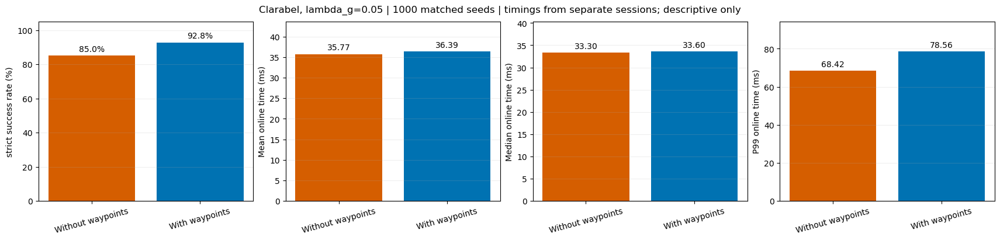

In [4]:
if not paired_seeds:
    print("No paired results yet. Existing graph results remain displayed in Sections 4.1 and 4.2.")
else:
    paired_rows = {mode: {r["seed"]: r for r in rows if r["seed"] in paired_seeds}
                   for mode, rows in comparison_rows.items()}
    timing_records, outcome_records = [], []
    for mode, rows in paired_rows.items():
        paths = [(EVAL_DIR / f"seed{s}_control_results.npz")
                 if mode == "graph" and not graph_is_fresh else
                 (WAYPOINT_RESULT_DIR / mode / f"seed{s}_control_results.npz") for s in paired_seeds]
        timing = summarize_timing(paths)
        timing_records.extend({"Method": clarabel_comparison.METHODS[mode], **row} for row in timing["modules"])
        outcome_records.append({"Method": clarabel_comparison.METHODS[mode],
            "Seeds": len(rows), "Successes": sum(r["success_30"] and r["success_100"] for r in rows.values()),
            "Median final-100 error (mm)": 1000*np.median([r["mean_last_100"] for r in rows.values()]),
            "Unsolved QPs": sum(r["unsolved_steps"] for r in rows.values())})
    outcomes = pd.DataFrame(outcome_records).set_index("Method")
    outcomes["Success rate (%)"] = 100*outcomes["Successes"]/outcomes["Seeds"]
    display(outcomes.round(3))
    graph_only = [s for s in paired_seeds
                  if paired_rows["graph"][s]["success_30"] and paired_rows["graph"][s]["success_100"]
                  and not (paired_rows["terminal"][s]["success_30"] and paired_rows["terminal"][s]["success_100"])]
    terminal_only = [s for s in paired_seeds
                     if paired_rows["terminal"][s]["success_30"] and paired_rows["terminal"][s]["success_100"]
                     and not (paired_rows["graph"][s]["success_30"] and paired_rows["graph"][s]["success_100"])]
    display(pd.Series({"With-waypoints-only successes": len(graph_only),
                       "Without-waypoints-only successes": len(terminal_only),
                       "Net successes added by waypoints": len(graph_only)-len(terminal_only)}))
    display(HTML("<details><summary>Seeds with different outcomes</summary>" +
        pd.Series({"With waypoints only": graph_only, "Without waypoints only": terminal_only})
        .to_frame().to_html() + "</details>"))
    timing_table = pd.DataFrame(timing_records)
    display(timing_table.pivot(index="module", columns="Method", values=["mean_ms", "median_ms", "p99_ms"]).round(4))
    fig, axes = plt.subplots(1, 4, figsize=(17, 4), constrained_layout=True)
    labels = ["Without waypoints", "With waypoints"]
    colors = ["#D55E00", "#0072B2"]
    rates = outcomes["Success rate (%)"].to_numpy()
    bars = axes[0].bar(labels, rates, color=colors)
    axes[0].bar_label(bars, fmt="%.1f%%", padding=3)
    axes[0].set(ylim=(0, 105), ylabel="strict success rate (%)")
    totals = timing_table[timing_table.module == "Total online control"]
    for ax, metric, label in zip(axes[1:], ["mean_ms", "median_ms", "p99_ms"], ["Mean", "Median", "P99"]):
        values = totals[metric].to_numpy()
        bars = ax.bar(labels, values, color=colors)
        ax.bar_label(bars, fmt="%.2f", padding=3)
        ax.set(ylim=(0, values.max()*1.2), ylabel=f"{label} online time (ms)")
    for ax in axes:
        ax.tick_params(axis="x", rotation=15)
        ax.grid(axis="y", alpha=.2)
    note = "new paired timing run" if graph_is_fresh else "timings from separate sessions; descriptive only"
    fig.suptitle(f"Clarabel, lambda_g=0.05 | {len(paired_seeds)} matched seeds | {note}")
    fig.savefig(WAYPOINT_RESULT_DIR / "waypoint_comparison.png", dpi=160, bbox_inches="tight")
    plt.show()
    report = {"solver": "CLARABEL", "lambda_g": .05, "seeds": paired_seeds,
              "outcomes": outcomes.reset_index().to_dict(orient="records"),
              "module_timing": timing_records, "timing_caveat": note,
              "with_waypoints_only": graph_only, "without_waypoints_only": terminal_only}
    (WAYPOINT_RESULT_DIR / "paired_comparison_report.json").write_text(json.dumps(report, indent=2))


## 5. Atlas routing replays

The original gallery format and seed IDs are restored below: ten representative
simulator replays followed by three diagnostic replays. Every video replays the
**linear-subspace + iterative N=10** baseline, and its measured outputs are checked
against the saved numerical rollout. Labels are recomputed from the current results,
not inherited from the old affine/fixed-reference method.

These are selected diagnostic examples, not a random success-rate panel. Simulator
replays retain the previous compact playback format; the dashboard section below
provides slowed 0.25x views. All videos are embedded for reliable notebook playback.


In [11]:
import base64
from baseline_notebook_media import (
    GALLERY_SEEDS, DIAGNOSTIC_VIDEO_SEEDS, ADDITIONAL_DASHBOARD_SEEDS,

)
from render_routed_deepc_dashboard import file_sha256

TRACE_DIR = RESULT_ROOT / "diagnostics"
VIDEO_DIR = RESULT_ROOT / "videos"
PREPARE_MEDIA = False
if PREPARE_MEDIA:
    raise RuntimeError("Historical media are loaded from saved files; regeneration is disabled here.")
video_summary = json.loads((TRACE_DIR / "summary.json").read_text())
assert video_summary["method"] == SAVED_BASELINE_VERSION
video_by_seed = {int(row["seed"]): row for row in video_summary["results"]}

def embedded_media(path, mime):
    return "data:" + mime + ";base64," + base64.b64encode(Path(path).read_bytes()).decode("ascii")

def media_card(seed, dashboard=False):
    row = video_by_seed[seed]
    assert row["baseline_version"] == SAVED_BASELINE_VERSION
    assert row["matrix_geometry"] == "linear" and row["candidate_count"] == 10
    trace = TRACE_DIR / f"seed{seed}_control_results.npz"
    name = f"seed{seed}_025x" if dashboard else f"seed{seed}_control"
    video = VIDEO_DIR / (name + ".mp4")
    metadata_path = VIDEO_DIR / (name + (".json" if dashboard else "_verification.json"))
    assert video.exists() and metadata_path.exists(), f"Prepare media first: {video}"
    metadata = json.loads(metadata_path.read_text())
    assert metadata["source_result_sha256"] == file_sha256(trace)
    if dashboard:
        assert metadata["play_speed"] == 0.25
    else:
        assert metadata["maximum_replay_output_error"] <= 1e-8
    success = bool(row["success_30"] and row["success_100"])
    status, color = ("SUCCESS", "#166534") if success else ("FAILURE", "#b91c1c")
    target = video_summary["fairness_audit"]["held_out_targets"][str(seed)]["target"]
    detail = f"Final-30 mean: {1000*row['mean_last_30']:.3f} mm | Target: ({target[0]:+.3f}, {target[1]:+.3f})"
    poster_attribute = ""
    if dashboard:
        poster = VIDEO_DIR / (name + "_poster.png")
        poster_attribute = f' poster="{embedded_media(poster, "image/png")}"'
        detail += f" | 0.25x | {metadata['displayed_control_steps']} of {metadata['saved_control_steps']} steps"
    return f"""<div style="border:1px solid #d1d5db;padding:10px;background:#fff;color:#111827;min-width:0">
      <div style="font:600 14px sans-serif;margin-bottom:6px">Seed {seed} &nbsp; <span style="color:{color}">{status}</span></div>
      <div style="font:12px sans-serif;margin-bottom:8px;color:#4b5563">{detail}</div>
      <video src="{embedded_media(video, 'video/mp4')}"{poster_attribute} controls preload="metadata"
             style="display:block;width:100%;background:#f5f7fa"></video></div>"""

def show_gallery(seeds, title, dashboard=False):
    width = 480 if dashboard else 280
    cards = "".join(media_card(seed, dashboard) for seed in seeds)
    display(HTML(f'<h3>{title}</h3><div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(min({width}px,100%),1fr));gap:14px">{cards}</div>'))

all_gallery_success = all(video_by_seed[s]["success_30"] and video_by_seed[s]["success_100"] for s in GALLERY_SEEDS)
show_gallery(GALLERY_SEEDS, "Ten representative baseline successes" if all_gallery_success else "Ten representative baseline rollouts (current outcomes)")
show_gallery(DIAGNOSTIC_VIDEO_SEEDS, "Baseline success and failure diagnostics")
print("All 13 simulator replays verified against the current baseline's numerical outputs.")


All 13 simulator replays verified against the current baseline's numerical outputs.


## 6. Slowed Atlas-routing dashboard

The main dashboard uses **seed 222**, followed by the original five additional
dashboard seeds. Each shows the measured arm, one-step DeePC prediction, active
waypoint posture, graph route, changing goal chart, target error, and applied inputs.
Playback is **0.25x**. The caption reports the actual displayed duration: new overview
dashboards use 60 steps; already available full-length current-baseline videos are
retained. Full 320-step results determine every success label.



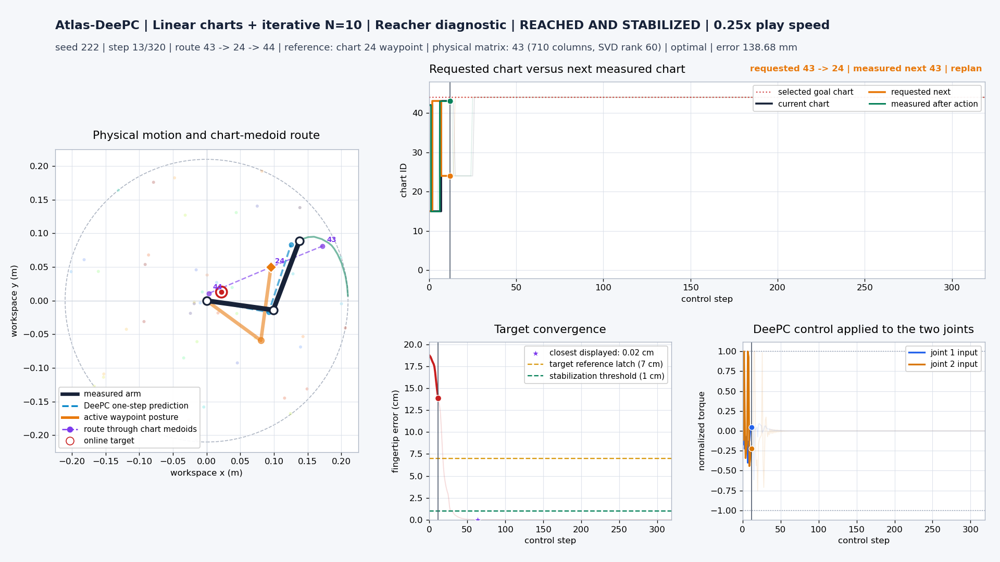

In [12]:
show_gallery([222], "Main slowed baseline dashboard", dashboard=True)



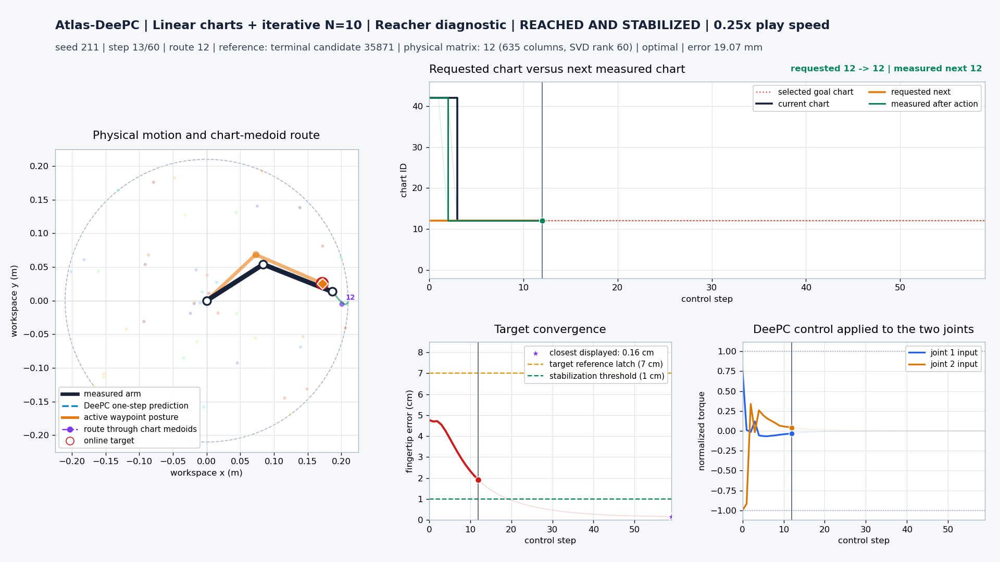
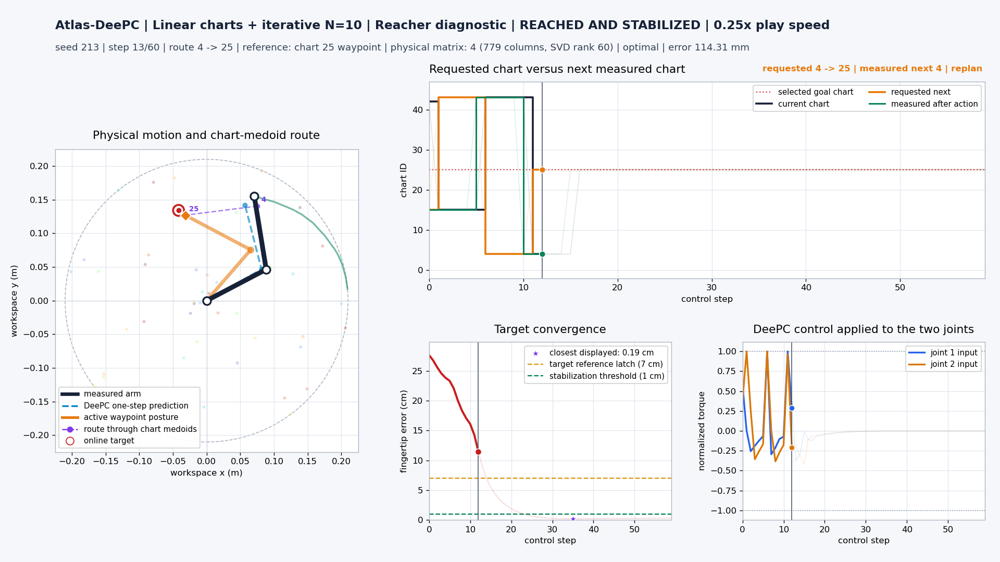
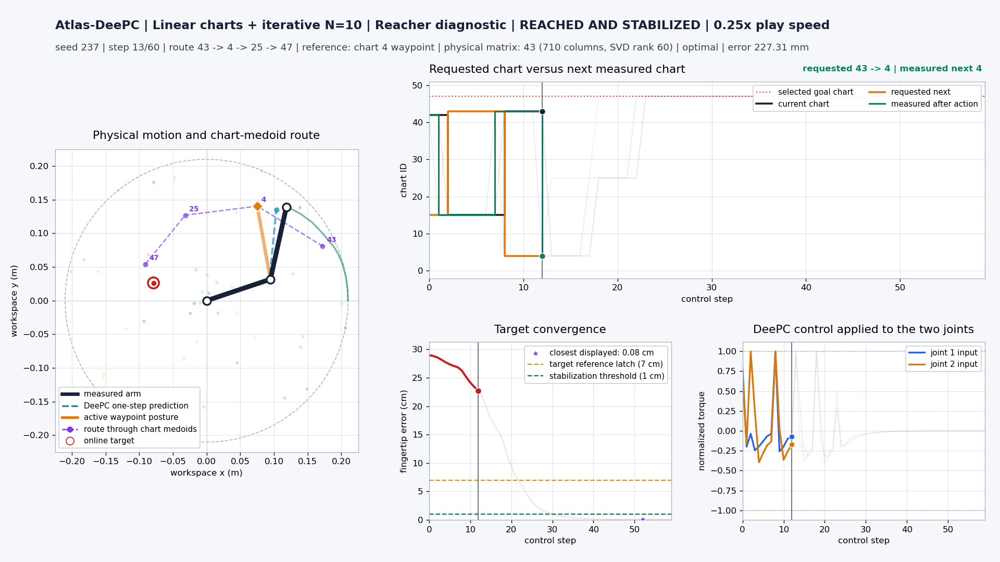
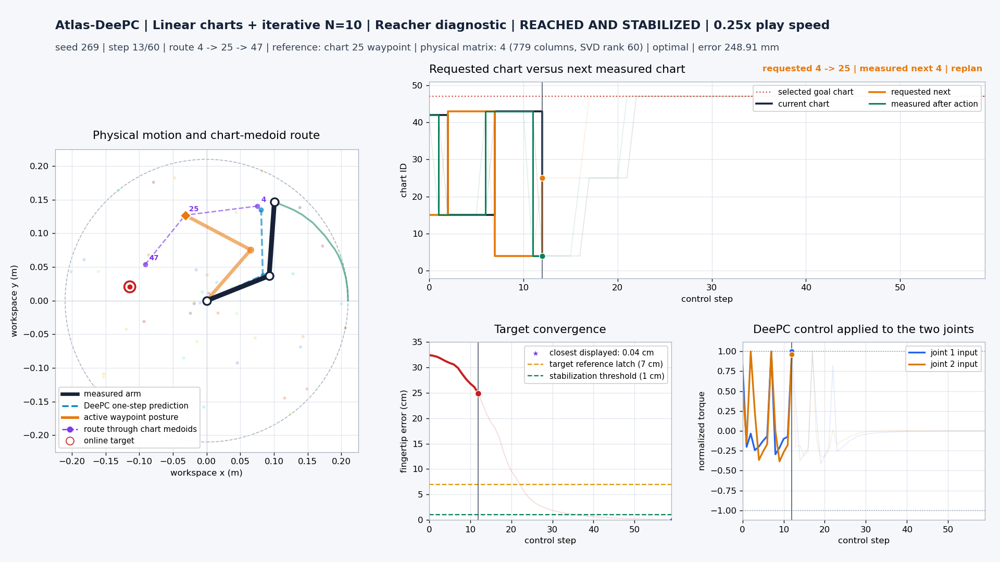
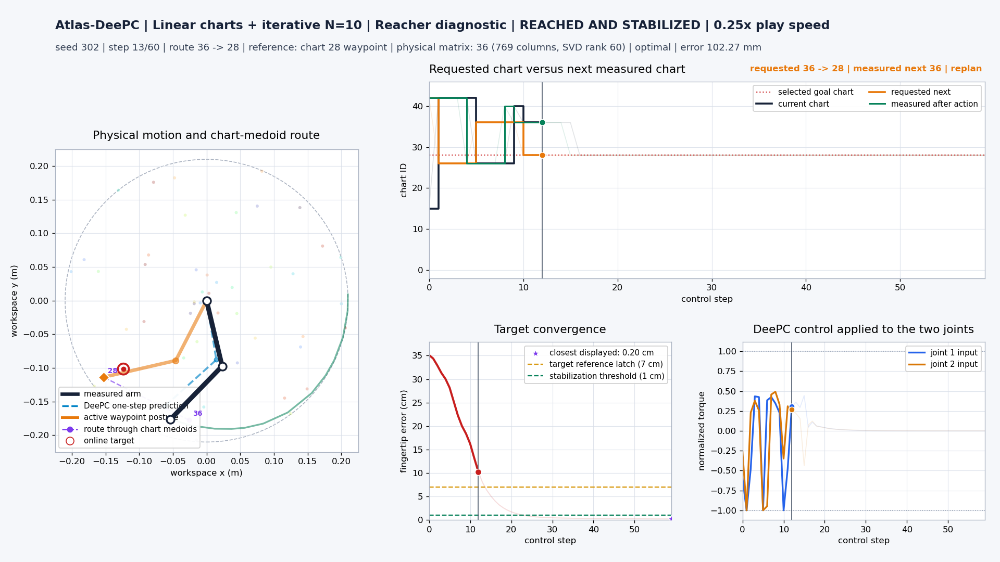

In [13]:
show_gallery(ADDITIONAL_DASHBOARD_SEEDS, "Five additional baseline dashboards", dashboard=True)


### Terminal stabilization diagnostic: seed 232

The full rollout is shown so late drift remains visible. The error and outcome below
come from the current baseline; no historical failure numbers are reused.


Seed 232: closest 13.481 mm; final-100 mean 13.481 mm; strict success = False



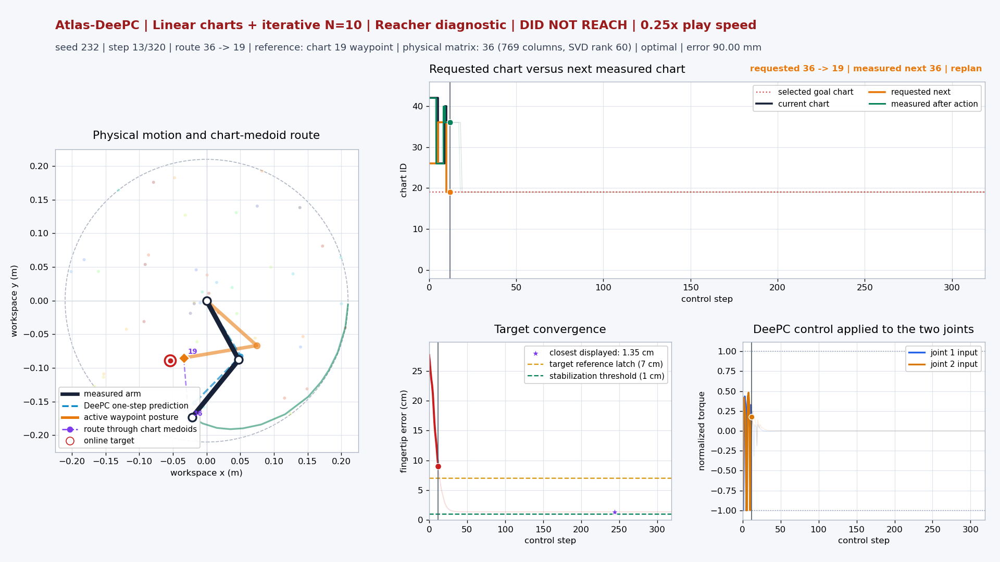

In [14]:
row = video_by_seed[232]
print(f"Seed 232: closest {1000*row['minimum']:.3f} mm; final-100 mean {1000*row['mean_last_100']:.3f} mm; strict success = {row['success_30'] and row['success_100']}")
show_gallery([232], "Seed 232: full terminal-stabilization diagnostic", dashboard=True)


### Former mechanical-failure case: seed 277

This is the same seed that failed in the old method. The new combined baseline's
saved rollout succeeds, so it is now labeled as a repaired example, not a current
mechanical failure. The complete rollout is retained for inspection.


Seed 277: closest 0.228 mm; final-100 mean 0.228 mm; strict success = True



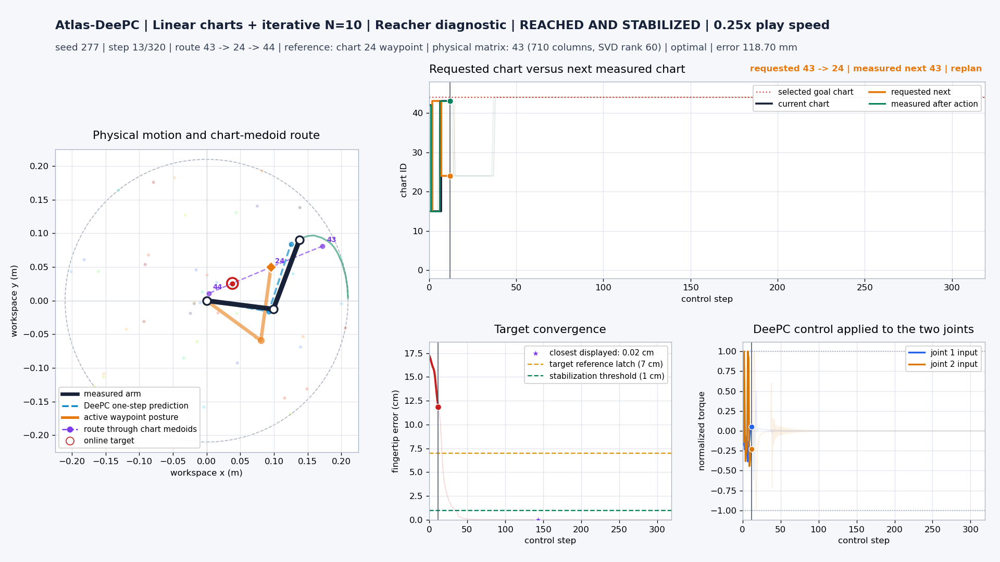

In [15]:
row = video_by_seed[277]
print(f"Seed 277: closest {1000*row['minimum']:.3f} mm; final-100 mean {1000*row['mean_last_100']:.3f} mm; strict success = {row['success_30'] and row['success_100']}")
show_gallery([277], "Seed 277: current-baseline outcome", dashboard=True)


## 7. Historical Result Boundary

This notebook restores the saved Clarabel, lambda_g=0.05 experiment only.
Running its analysis cells reads existing results; it does not repeat the simulations.
Shared controller modules and newer OSQP experiment data have not been changed.
The saved latency includes QP construction and solving and excludes simulation and rendering.
